# Práctica 4: Ensambles de Modelos
**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación — CICESE  
**Profesor:** Dr. Irvin Hussein López Nava  
**Estudiante:** Luis Felipe García Domínguez  

---

## 1. Preparación del entorno y recuperación de los clasificadores base

En esta práctica analizamos el impacto y la ganancia de los métodos de ensamble sobre clasificadores supervisados previamente optimizados en la Práctica 3. Iniciamos preparando el entorno de trabajo y configurando las particiones de validación cruzada.

Para la primera parte de la práctica, recuperamos los cinco clasificadores base individuales optimizados en la Práctica 3 para el problema de deserción estudiantil (`desercion-entrenamiento.csv`), considerando la restricción de predecir al cierre del primer semestre (se excluyen variables del segundo semestre):
1. **Árbol de Decisión** (con poda CCP y control de profundidad)
2. **Naive Bayes** (`CategoricalNB` con discretización de cuantiles)
3. **k Vecinos más Cercanos — kNN** (con distancia Manhattan y selección supervisada)
4. **Máquinas de Soporte Vectorial — SVM** (con kernel RBF)
5. **Regresión Logística** (con penalización $L_2$ y rangos binarizados)

A diferencia de la Práctica 3 (donde empleamos 10 pliegues), aquí evaluamos los cinco modelos base bajo 5 pliegues estratificados (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`), fijando la línea base que servirá de referencia para contrastar los ensambles por reducción de varianza (Bagging, Random Forest, Extra-Trees), reducción de sesgo (AdaBoost, Gradient Boosting) y combinación heterogénea (Voting y Stacking).

In [1]:
# Librerías necesarias para la práctica
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import lightgbm as lgb
import joblib

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV, TunedThresholdClassifierCV
from sklearn.metrics import f1_score, accuracy_score, recall_score, make_scorer, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, KBinsDiscretizer, FunctionTransformer, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier
)

# Manejo de advertencias para mantener salidas limpias
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Semillas fijas
SEMILLA = 42
SEMILLA_BANK = 2026

# Paleta visual uniforme
AZUL_OSCURO = "#1F2D3D"
AZUL = "#2E5B88"
AZUL_MEDIO = "#4A7BB0"
AZUL_CLARO = "#8EAECF"
NARANJA = "#D96B27"
ROJO = "#C0392B"
VERDE = "#27AE60"
GRIS = "#BDC3C7"

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 0.8

print("Versiones de librerías instaladas:")
print(f"  • pandas       : {pd.__version__}")
print(f"  • numpy        : {np.__version__}")
print(f"  • scikit-learn : {sklearn.__version__}")
print(f"  • xgboost      : {xgb.__version__}")
print(f"  • lightgbm     : {lgb.__version__}")
print(f"  • joblib       : {joblib.__version__}")

Versiones de librerías instaladas:
  • pandas       : 3.0.6
  • numpy        : 2.5.3
  • scikit-learn : 1.9.1
  • xgboost      : 3.4.1
  • lightgbm     : 4.7.0
  • joblib       : 1.6.0


### Carga de datos de deserción estudiantil y extracción de indicadores

Cargamos el conjunto de entrenamiento de deserción estudiantil (`desercion-entrenamiento.csv`) y aplicamos la restricción temporal del primer semestre: descartamos el identificador administrativo `id`, la variable objetivo `Target` de la matriz predictora y las 6 variables del segundo semestre.

Al igual que en la práctica previa, aplicamos la función `agregar_indicadores_1er_semestre` encapsulada en un `FunctionTransformer` dentro del `Pipeline`. Esto calcula razones académicas (tasa de aprobación, materias reprobadas, evaluaciones extraordinarias) e indicadores de riesgo financiero (`deudor_sin_colegiatura`) estrictamente dentro de cada partición de entrenamiento.

In [2]:
# Carga de datos con ruta relativa
RUTA_DATOS = Path("../data")
entrena_crudo = pd.read_csv(RUTA_DATOS / "desercion-entrenamiento.csv")

# Columnas del segundo semestre que se excluyen para la predicción al 1er semestre
COLUMNAS_2S = [
    "Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)"
]
COLUMNAS_1S = [c for c in entrena_crudo.columns if c not in COLUMNAS_2S and c not in ["id", "Target"]]

NOMINALES_MULTICLASE = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]
BINARIOS = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International"
]
NUMERICOS_DISCRETOS_1S = [
    "Application order", "Age at enrollment",
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (without evaluations)"
]
NUMERICOS_CONTINUOS_1S = [
    "Previous qualification (grade)", "Admission grade",
    "Curricular units 1st sem (grade)",
    "Unemployment rate", "Inflation rate", "GDP"
]
NUMERICOS_1S = NUMERICOS_DISCRETOS_1S + NUMERICOS_CONTINUOS_1S

X_desercion = entrena_crudo[COLUMNAS_1S].copy()
y_desercion = entrena_crudo["Target"].copy()
CLASES_DESERCION = ["Dropout", "Enrolled", "Graduate"]

def agregar_indicadores_1er_semestre(df):
    '''Calcula razones e indicadores de rendimiento del primer semestre'''
    df = df.copy()
    inscritas = df["Curricular units 1st sem (enrolled)"]
    aprobadas = df["Curricular units 1st sem (approved)"]
    evaluadas = df["Curricular units 1st sem (evaluations)"]
    nota = df["Curricular units 1st sem (grade)"]

    df["tasa_aprobacion_1s"] = np.where(inscritas > 0, aprobadas / inscritas, 0.0)
    df["tasa_aprob_eval_1s"] = np.where(evaluadas > 0, aprobadas / evaluadas, 0.0)
    df["tasa_evaluacion_1s"] = np.where(inscritas > 0, evaluadas / inscritas, 0.0)
    df["reprobadas_1s"] = np.maximum(0, inscritas - aprobadas)
    df["eval_fallidas_1s"] = np.maximum(0, evaluadas - aprobadas)
    df["eval_extra_1s"] = np.maximum(0, evaluadas - inscritas)

    df["sin_unidades_1s"] = (inscritas == 0).astype(int)
    df["nota_cero_1s"] = (nota == 0).astype(int)
    df["todo_aprobado_1s"] = ((inscritas > 0) & (aprobadas == inscritas)).astype(int)
    df["nada_aprobado_1s"] = ((inscritas > 0) & (aprobadas == 0)).astype(int)
    df["aprobacion_parcial_1s"] = ((aprobadas > 0) & (aprobadas < inscritas)).astype(int)
    df["reprobo_una_o_dos_1s"] = ((inscritas > 0) & ((inscritas - aprobadas).isin([1, 2]))).astype(int)
    df["reprobo_tres_o_mas_1s"] = ((inscritas - aprobadas) >= 3).astype(int)

    df["puntos_totales_1s"] = aprobadas * nota
    df["dif_admision_previa"] = df["Admission grade"] - df["Previous qualification (grade)"]
    df["deudor_sin_colegiatura"] = ((df["Debtor"] == 1) | (df["Tuition fees up to date"] == 0)).astype(int)
    df["colegiatura_y_todo_aprob"] = ((df["Tuition fees up to date"] == 1) & (df["todo_aprobado_1s"] == 1)).astype(int)
    df["mayor_23_ingreso"] = (df["Age at enrollment"] >= 23).astype(int)
    return df

# Identificación de columnas generadas para alimentar los ColumnTransformers
muestra_trans = agregar_indicadores_1er_semestre(X_desercion.head(5))
NUEVAS_BIN = [
    "sin_unidades_1s", "nota_cero_1s", "todo_aprobado_1s",
    "nada_aprobado_1s", "aprobacion_parcial_1s",
    "reprobo_una_o_dos_1s", "reprobo_tres_o_mas_1s",
    "deudor_sin_colegiatura", "colegiatura_y_todo_aprob", "mayor_23_ingreso"
]
NUEVAS_NUM = [c for c in muestra_trans.columns if c not in COLUMNAS_1S and c not in NUEVAS_BIN]
NUMERICOS_TOTAL = NUMERICOS_1S + NUEVAS_NUM
BINARIOS_TOTAL = BINARIOS + NUEVAS_BIN

print(f"Dimensiones de entrenamiento : {X_desercion.shape[0]} estudiantes × {X_desercion.shape[1]} atributos originales")
print(f"Atributos tras indicadores   : {muestra_trans.shape[1]} columnas ({len(NUMERICOS_TOTAL)} numéricas, {len(BINARIOS_TOTAL)} binarias, {len(NOMINALES_MULTICLASE)} nominales)")

Dimensiones de entrenamiento : 3539 estudiantes × 30 atributos originales
Atributos tras indicadores   : 48 columnas (21 numéricas, 18 binarias, 9 nominales)


### Reconstrucción de los cinco clasificadores base

Reconstruimos los `Pipeline` completos de los cinco modelos con sus preprocesadores específicos y los mejores hiperparámetros identificados en la Práctica 3, utilizando el esquema de pesos moderados (`PESOS_SUAVES`) para los clasificadores que admiten balanceo de clases.

In [3]:
# Pesos moderados por clase optimizados en la Práctica 3
# Incluimos llaves de texto y numéricas para compatibilidad con Voting y Stacking
PESOS_SUAVES = {
    "Dropout": 0.95, "Enrolled": 1.60, "Graduate": 0.75,
    0: 0.95, 1: 1.60, 2: 0.75
}

# 1. Árbol de Decisión
pre_arbol = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", "passthrough", NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])
pipe_arbol = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
    ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=6, min_samples_leaf=10, ccp_alpha=0.002, class_weight=PESOS_SUAVES, random_state=SEMILLA)),
])

# 2. Naive Bayes (CategoricalNB discretizado por cuantiles)
pre_nb = ColumnTransformer([
    ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=99, encoded_missing_value=99), NOMINALES_MULTICLASE),
    ("num", KBinsDiscretizer(n_bins=6, encode="ordinal", strategy="quantile"), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])
pipe_nb = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_nb),
    ("clf", CategoricalNB(min_categories=105, alpha=0.01)),
])

# 3. k Vecinos más Cercanos (kNN con selección y distancia Manhattan)
pre_knn = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])
pipe_knn = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_knn),
    ("sel", SelectKBest(f_classif, k=40)),
    ("esc", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=13, p=1, weights="uniform")),
])

# 4. Máquinas de Soporte Vectorial (SVM con kernel Gaussiano RBF)
pre_svm = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])
pipe_svm = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_svm),
    ("clf", SVC(C=1.2, gamma="scale", kernel="rbf", class_weight=PESOS_SUAVES, cache_size=500, random_state=SEMILLA)),
])

# 5. Regresión Logística (L2 con binarización escalonada en variables clave)
COLS_BINS = [
    "Age at enrollment", "Admission grade", "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
    "tasa_aprobacion_1s", "reprobadas_1s"
]
pre_log = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=8, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bins", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), COLS_BINS),
    ("bin", "passthrough", BINARIOS_TOTAL),
])
pipe_log = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_log),
    ("clf", LogisticRegression(C=0.3, penalty="l2", solver="lbfgs", class_weight=PESOS_SUAVES, max_iter=800, random_state=SEMILLA)),
])

modelos_base = {
    "Árbol de decisión": pipe_arbol,
    "Naive Bayes (CategoricalNB)": pipe_nb,
    "k Vecinos (kNN)": pipe_knn,
    "SVM (RBF)": pipe_svm,
    "Regresión Logística": pipe_log,
}

### Evaluación en 5 pliegues estratificados (Línea Base)

Evaluamos los cinco clasificadores base utilizando la partición estratificada de 5 pliegues (`StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)`). Registramos el F1 macro (media y desviación entre pliegues), exactitud global, sensibilidad sobre la clase minoritaria `Enrolled` y el tiempo de cómputo.

In [4]:
# Partición oficial de 5 pliegues para deserción estudiantil
cv5_desercion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def sens_enrolled(y_true, y_pred):
    primero = y_true.iloc[0] if hasattr(y_true, 'iloc') else y_true[0]
    etiqueta = 1 if isinstance(primero, (int, np.integer)) else 'Enrolled'
    return recall_score(y_true, y_pred, labels=[etiqueta], average=None)[0]

metricas_eval = {
    "f1_macro": "f1_macro",
    "exactitud": "accuracy",
    "sens_enrolled": make_scorer(sens_enrolled),
}

filas_base = []
for nombre, modelo in modelos_base.items():
    inicio_t = time.perf_counter()
    resultado = cross_validate(modelo, X_desercion, y_desercion, cv=cv5_desercion, scoring=metricas_eval, n_jobs=-1)
    tiempo_total = time.perf_counter() - inicio_t
    filas_base.append({
        "Modelo": nombre,
        "Familia": "Base individual",
        "F1 macro (media)": resultado["test_f1_macro"].mean(),
        "F1 macro (desv)": resultado["test_f1_macro"].std(),
        "Exactitud": resultado["test_exactitud"].mean(),
        "Sensibilidad Enrolled": resultado["test_sens_enrolled"].mean(),
        "Tiempo (s)": tiempo_total,
    })

tabla_base = pd.DataFrame(filas_base).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)

tabla_base_mostrar = tabla_base.copy()
tabla_base_mostrar["F1 macro"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(tabla_base["F1 macro (media)"], tabla_base["F1 macro (desv)"])]
tabla_base_mostrar["Exactitud"] = [f"{v * 100:.2f} %" for v in tabla_base["Exactitud"]]
tabla_base_mostrar["Sensibilidad Enrolled"] = [f"{v * 100:.2f} %" for v in tabla_base["Sensibilidad Enrolled"]]
tabla_base_mostrar["Tiempo (s)"] = [f"{v:.2f} s" for v in tabla_base["Tiempo (s)"]]

display(tabla_base_mostrar[["Modelo", "Familia", "F1 macro", "Exactitud", "Sensibilidad Enrolled", "Tiempo (s)"]])

,Modelo,Familia,F1 macro,Exactitud,Sensibilidad Enrolled,Tiempo (s)
0,Regresión Logística,Base individual,0.6862 ± 0.0176,73.52 %,54.02 %,0.79 s
1,SVM (RBF),Base individual,0.6743 ± 0.0100,72.59 %,51.97 %,1.04 s
2,Naive Bayes (CategoricalNB),Base individual,0.6507 ± 0.0130,69.65 %,53.07 %,0.72 s
3,Árbol de decisión,Base individual,0.6456 ± 0.0167,68.27 %,57.64 %,1.20 s
4,k Vecinos (kNN),Base individual,0.6451 ± 0.0101,73.07 %,31.02 %,0.81 s


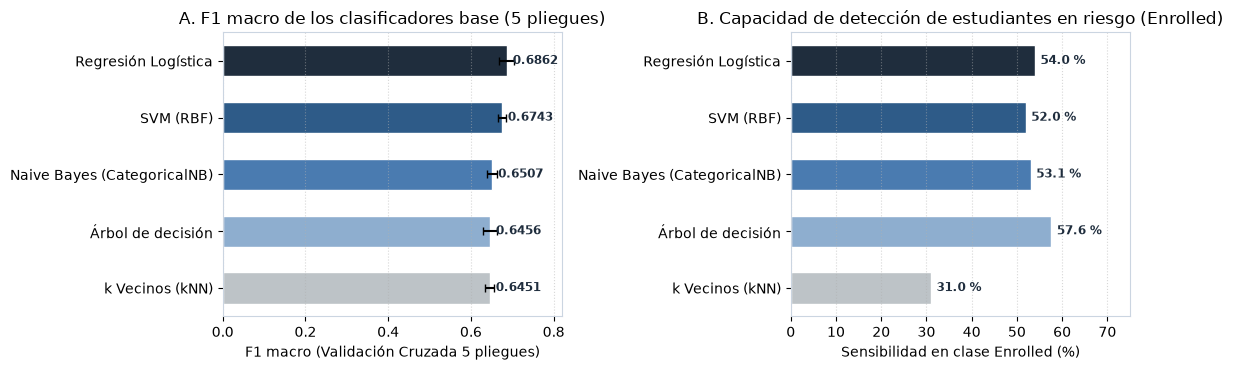

In [5]:
# Gráfica de desempeño de los 5 clasificadores base
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8))

modelos_ordenados = tabla_base["Modelo"].tolist()
f1_valores = tabla_base["F1 macro (media)"].tolist()
f1_errores = tabla_base["F1 macro (desv)"].tolist()
rec_enrolled = tabla_base["Sensibilidad Enrolled"].tolist()

colores_barras = [AZUL_OSCURO, AZUL, AZUL_MEDIO, AZUL_CLARO, GRIS]

# Panel A: F1 Macro
barras1 = ax1.barh(modelos_ordenados[::-1], f1_valores[::-1], xerr=f1_errores[::-1],
                   color=colores_barras[::-1], edgecolor="white", height=0.55, capsize=3)
for b, val in zip(barras1, f1_valores[::-1]):
    ax1.text(val + 0.015, b.get_y() + b.get_height() / 2, f"{val:.4f}", va="center", fontsize=8.5, fontweight="bold", color=AZUL_OSCURO)

ax1.set_xlim(0, 0.82)
ax1.set_xlabel("F1 macro (Validación Cruzada 5 pliegues)")
ax1.set_title("A. F1 macro de los clasificadores base (5 pliegues)")
ax1.grid(axis="x", linestyle=":", alpha=0.5)

# Panel B: Sensibilidad en Enrolled
barras2 = ax2.barh(modelos_ordenados[::-1], [r * 100 for r in rec_enrolled[::-1]],
                   color=colores_barras[::-1], edgecolor="white", height=0.55)
for b, val in zip(barras2, rec_enrolled[::-1]):
    ax2.text(val * 100 + 1.2, b.get_y() + b.get_height() / 2, f"{val * 100:.1f} %", va="center", fontsize=8.5, fontweight="bold", color=AZUL_OSCURO)

ax2.set_xlim(0, 75)
ax2.set_xlabel("Sensibilidad en clase Enrolled (%)")
ax2.set_title("B. Capacidad de detección de estudiantes en riesgo (Enrolled)")
ax2.grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

**Lectura.** Al evaluar los cinco clasificadores base bajo la partición de 5 pliegues estratificados, observamos un rendimiento muy consistente con los resultados de la Práctica 3:

1. **Regresión Logística** es el mejor modelo con un **F1 macro de `0.6862 ± 0.0176`** y una sensibilidad del **54.02 %** en `Enrolled`, beneficiada por la discretización en rangos y los pesos moderados de clase.
2. **SVM con kernel RBF** queda en un segundo lugar muy cercano (**`0.6743 ± 0.0100`**), mostrando además la menor varianza entre pliegues.
3. **Naive Bayes (`CategoricalNB`)** alcanza **`0.6507 ± 0.0130`**, superando al árbol y a kNN gracias a la discretización por cuantiles, aunque limitado por la suposición de independencia entre materias aprobadas y reprobadas.
4. **Árbol de Decisión podado** obtiene **`0.6456 ± 0.0167`** pero destaca por la mayor sensibilidad individual en la clase minoritaria (**57.64 %**), aunque sus cortes limitan la exactitud global.
5. **k Vecinos (kNN)** queda en quinto lugar (**`0.6451 ± 0.0101`**), afectado por la densidad dispersa de la clase `Enrolled` en el espacio de distancias (sensibilidad de apenas 31.02 %).

Estos resultados establecen la línea base sobre la cual mediremos si los métodos de ensamble (Bagging, Boosting y Stacking) logran superar el umbral de `0.6862` de la Regresión Logística y mejorar la detección de alumnos en riesgo.

---

## 2. Reducción de varianza y sesgo

Los métodos de ensamble combinan múltiples estimadores para producir un modelo más robusto. La teoría nos dice que existen dos vías principales para mejorar el desempeño de un clasificador:

1. **Reducción de varianza (Bagging):** Promediar modelos con bajo sesgo pero alta varianza (como árboles profundos sin podar) para reducir la inestabilidad de las predicciones.

2. **Reducción de sesgo (Boosting):** Combinar secuencialmente modelos con alto sesgo pero baja varianza (como tocones de decisión de un solo nivel), donde cada modelo nuevo se enfoca en corregir los errores cometidos por los anteriores.

En esta sección evaluamos ambas estrategias sobre el conjunto de deserción estudiantil.

### 2.1. Reducción de varianza: Árbol sin límite de profundidad vs. Bagging

Comparamos el desempeño de un árbol de decisión sin restricción de profundidad (`max_depth=None`), que tiende a sobreajustarse al memorizar elementos de la muestra de entrenamiento, frente a un ensamble de **Bagging** (`BaggingClassifier`) construido con esos mismos árboles.

Para analizar cómo cambia el rendimiento con el tamaño del ensamble, evaluamos distintas cantidades de árboles: $1, 5, 10, 20, 50, 100, 200, 300 \text{ y }400$. Usamos el parámetro `warm_start=True` para agregar árboles progresivamente sin tener que reentrenar el ensamble desde cero en cada evaluación.

In [6]:
# Preprocesamiento base para modelos basados en árboles
pipe_pre_arbol = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
])

# 1. Árbol sin límite de profundidad
pipe_arbol_libre = Pipeline([
    ("pre", pipe_pre_arbol),
    ("clf", DecisionTreeClassifier(max_depth=None, random_state=SEMILLA)),
])

res_arbol_libre = cross_validate(
    pipe_arbol_libre, X_desercion, y_desercion, cv=cv5_desercion,
    scoring="f1_macro", return_train_score=True, n_jobs=-1
)
f1_libre_tr = res_arbol_libre["train_score"].mean()
f1_libre_media = res_arbol_libre["test_score"].mean()
f1_libre_desv = res_arbol_libre["test_score"].std()

print(f"Árbol sin límite (max_depth=None): F1 entrenamiento = {f1_libre_tr:.3f}, validación = {f1_libre_media:.4f} ± {f1_libre_desv:.4f}")

# 2. Bagging con warm_start de 1 a 400 árboles
cantidades_arboles = [1, 5, 10, 20, 50, 100, 200, 300, 400]
bag_val_scores = {n: [] for n in cantidades_arboles}
bag_tr_scores = {n: [] for n in cantidades_arboles}

inicio_bag = time.perf_counter()

for train_idx, val_idx in cv5_desercion.split(X_desercion, y_desercion):
    X_tr_t = pipe_pre_arbol.fit_transform(X_desercion.iloc[train_idx], y_desercion.iloc[train_idx])
    X_val_t = pipe_pre_arbol.transform(X_desercion.iloc[val_idx])
    y_tr = y_desercion.iloc[train_idx]
    y_val = y_desercion.iloc[val_idx]

    bag = BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=None, random_state=SEMILLA),
        warm_start=True,
        random_state=SEMILLA,
        n_jobs=-1
    )

    for n in cantidades_arboles:
        bag.n_estimators = n
        bag.fit(X_tr_t, y_tr)
        bag_val_scores[n].append(f1_score(y_val, bag.predict(X_val_t), average="macro"))
        bag_tr_scores[n].append(f1_score(y_tr, bag.predict(X_tr_t), average="macro"))

tiempo_bag = time.perf_counter() - inicio_bag
print(f"Evaluación de Bagging completada en {tiempo_bag:.1f} s")

curva_bag_val = [np.mean(bag_val_scores[n]) for n in cantidades_arboles]
curva_bag_tr = [np.mean(bag_tr_scores[n]) for n in cantidades_arboles]
curva_bag_desv = [np.std(bag_val_scores[n]) for n in cantidades_arboles]
for n, media, desv in zip(cantidades_arboles, curva_bag_val, curva_bag_desv):
    if n in [1, 20, 200, 300, 400]:
        print(f"  {n:3d} árboles: F1 validación = {media:.4f} ± {desv:.4f}")

Árbol sin límite (max_depth=None): F1 entrenamiento = 1.000, validación = 0.5961 ± 0.0185


Evaluación de Bagging completada en 40.1 s
    1 árboles: F1 validación = 0.5861 ± 0.0138
   20 árboles: F1 validación = 0.6526 ± 0.0147
  200 árboles: F1 validación = 0.6606 ± 0.0277
  300 árboles: F1 validación = 0.6638 ± 0.0263
  400 árboles: F1 validación = 0.6602 ± 0.0250


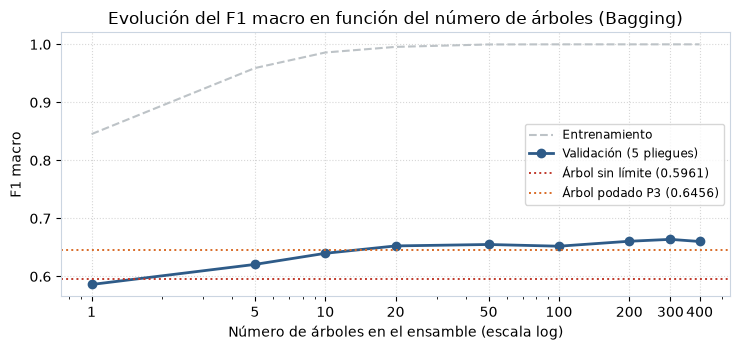

In [7]:
# Gráfica de la curva de Bagging
fig, ax = plt.subplots(figsize=(7.5, 3.6))

ax.plot(cantidades_arboles, curva_bag_tr, color=GRIS, linestyle="--", linewidth=1.5, label="Entrenamiento")
ax.plot(cantidades_arboles, curva_bag_val, color=AZUL, marker="o", linewidth=2, label="Validación (5 pliegues)")
ax.axhline(f1_libre_media, color=ROJO, linestyle=":", linewidth=1.4, label=f"Árbol sin límite ({f1_libre_media:.4f})")
ax.axhline(0.6456, color=NARANJA, linestyle=":", linewidth=1.4, label="Árbol podado P3 (0.6456)")

ax.set_xscale("log")
ax.set_xticks(cantidades_arboles)
ax.set_xticklabels([str(n) for n in cantidades_arboles])
ax.set_xlabel("Número de árboles en el ensamble (escala log)")
ax.set_ylabel("F1 macro")
ax.set_title("Evolución del F1 macro en función del número de árboles (Bagging)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="center right", fontsize=8.5, frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

**Lectura.** 

**¿Qué reduce Bagging y por qué?**  
Bagging reduce principalmente la varianza de las predicciones sin incrementar el sesgo. Un único árbol sin límite de profundidad memoriza características específicas y el ruido del conjunto de entrenamiento, lo que se traduce en un F1 de entrenamiento de 1.000 pero un desempeño pobre en validación (`0.5961 ± 0.0185`).

Al generar múltiples muestras con reemplazo (bootstrap) y entrenar un árbol independiente en cada una, los errores aleatorios de cada árbol individual tienden a cancelarse al promediar sus decisiones. Matemáticamente, el promedio de $L$ estimadores con varianza $\sigma^2$ y correlación media $\rho$ tiene varianza:
$$\mathrm{Var}\left(\frac{1}{L}\sum_{l=1}^{L} f_l\right) = \rho\sigma^2 + \frac{1-\rho}{L}\sigma^2$$

A medida que agregamos árboles, el término $\frac{1-\rho}{L}\sigma^2$ tiende a cero y la varianza total se reduce hasta el límite impuesto por la correlación entre árboles $\rho\sigma^2$.

En la gráfica observamos este efecto: pasar de 1 a 20 árboles incrementa el F1 macro de `0.5861` a `0.6526`, y a partir de 200 árboles (`0.6606`) la curva entra en una meseta que alcanza `0.6638 ± 0.0263` en 300 árboles, superando tanto al árbol sin límite como al árbol podado individual (`0.6456`).

### 2.2. Reducción de sesgo: Tocón de decisión vs. AdaBoost

Ahora se presenta la vía opuesta: Partimos de un modelo con alto sesgo (un **tocón** o árbol de profundidad 1, `max_depth=1`) y aplicamos **AdaBoost** (`AdaBoostClassifier`) para reducir dicho sesgo a lo largo de 400 rondas.

Utilizamos el método `staged_predict()` para obtener las predicciones del ensamble tras cada ronda de boosting en los pliegues de validación, registrando cómo cambia el F1 macro ronda por ronda.

In [8]:
# 1. Tocón de decisión
pipe_tocon = Pipeline([
    ("pre", pipe_pre_arbol),
    ("clf", DecisionTreeClassifier(max_depth=1, random_state=SEMILLA)),
])
res_tocon = cross_validate(pipe_tocon, X_desercion, y_desercion, cv=cv5_desercion, scoring="f1_macro", n_jobs=-1)
f1_tocon_media = res_tocon["test_score"].mean()
f1_tocon_desv = res_tocon["test_score"].std()

print(f"Tocón individual (max_depth=1)   : F1 macro = {f1_tocon_media:.4f} ± {f1_tocon_desv:.4f}")

# 2. AdaBoost con tocones evaluado con staged_predict
rondas_ada = 400
ada_val_pliegues = []
ada_tr_pliegues = []

inicio_ada = time.perf_counter()

for train_idx, val_idx in cv5_desercion.split(X_desercion, y_desercion):
    X_tr_t = pipe_pre_arbol.fit_transform(X_desercion.iloc[train_idx], y_desercion.iloc[train_idx])
    X_val_t = pipe_pre_arbol.transform(X_desercion.iloc[val_idx])
    y_tr = y_desercion.iloc[train_idx]
    y_val = y_desercion.iloc[val_idx]

    ada = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=SEMILLA),
        n_estimators=rondas_ada,
        random_state=SEMILLA
    )
    ada.fit(X_tr_t, y_tr)

    f1_val_etapas = [f1_score(y_val, p, average="macro") for p in ada.staged_predict(X_val_t)]
    f1_tr_etapas = [f1_score(y_tr, p, average="macro") for p in ada.staged_predict(X_tr_t)]

    ada_val_pliegues.append(f1_val_etapas)
    ada_tr_pliegues.append(f1_tr_etapas)

tiempo_ada = time.perf_counter() - inicio_ada
curva_ada_val = np.mean(ada_val_pliegues, axis=0)
curva_ada_tr = np.mean(ada_tr_pliegues, axis=0)

mejor_ronda_ada = int(np.argmax(curva_ada_val)) + 1
mejor_f1_ada = curva_ada_val[mejor_ronda_ada - 1]

print(f"AdaBoost (400 rondas) completado en {tiempo_ada:.1f} s")
print(f"Ronda 1   : F1 validación = {curva_ada_val[0]:.4f}")
print(f"Ronda 50  : F1 validación = {curva_ada_val[49]:.4f}")
print(f"Ronda 100 : F1 validación = {curva_ada_val[99]:.4f}")
print(f"Ronda 400 : F1 validación = {curva_ada_val[399]:.4f}")
print(f"Mejor desempeño: ronda {mejor_ronda_ada} con F1 = {mejor_f1_ada:.4f}")

Tocón individual (max_depth=1)   : F1 macro = 0.5082 ± 0.0120


AdaBoost (400 rondas) completado en 20.2 s
Ronda 1   : F1 validación = 0.5082
Ronda 50  : F1 validación = 0.5832
Ronda 100 : F1 validación = 0.6245
Ronda 400 : F1 validación = 0.6573
Mejor desempeño: ronda 396 con F1 = 0.6581


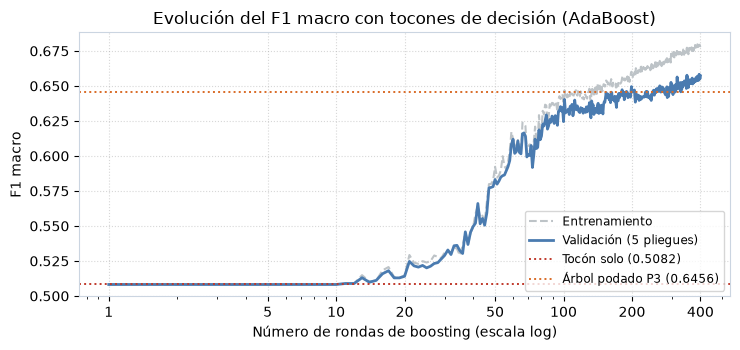

In [9]:
# Gráfica de la curva de AdaBoost
fig, ax = plt.subplots(figsize=(7.5, 3.6))

eje_rondas = np.arange(1, rondas_ada + 1)
ax.plot(eje_rondas, curva_ada_tr, color=GRIS, linestyle="--", linewidth=1.5, label="Entrenamiento")
ax.plot(eje_rondas, curva_ada_val, color=AZUL_MEDIO, linewidth=2, label="Validación (5 pliegues)")
ax.axhline(f1_tocon_media, color=ROJO, linestyle=":", linewidth=1.4, label=f"Tocón solo ({f1_tocon_media:.4f})")
ax.axhline(0.6456, color=NARANJA, linestyle=":", linewidth=1.4, label="Árbol podado P3 (0.6456)")

ax.set_xscale("log")
ax.set_xticks([1, 5, 10, 20, 50, 100, 200, 400])
ax.set_xticklabels(["1", "5", "10", "20", "50", "100", "200", "400"])
ax.set_xlabel("Número de rondas de boosting (escala log)")
ax.set_ylabel("F1 macro")
ax.set_title("Evolución del F1 macro con tocones de decisión (AdaBoost)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

**Lectura.** 

**¿Qué reduce Boosting y por qué?**  
Boosting reduce principalmente el **sesgo** del modelo. Un tocón de decisión solo puede formular una única pregunta binaria sobre una variable (por ejemplo, *¿materias aprobadas $\le 2$?*), lo que le impide capturar interacciones entre otras variables como notas, situación financiera o becas. Como resultado, un tocón solo tiene un sesgo grande y su desempeño es de apenas `0.5082 ± 0.0120`.

A diferencia de Bagging (que entrena en paralelo sobre muestras bootstrap independientes), AdaBoost entrena de forma secuencial. En cada ronda, los estudiantes que el tocón anterior clasificó erróneamente reciben un peso mayor, forzando al siguiente tocón a enfocarse en los casos desatendidos. Al sumar ponderadamente las decisiones de estos clasificadores débiles, el ensamble construye fronteras de decisión que van aumentando en complejidad. La curva muestra cómo el F1 macro sube de `0.5082` en la primera ronda hasta `0.6581` en la ronda 396 (+15 puntos de ganancia), eliminando el sesgo inicial y superando al árbol de decisión podado.

---

## 3. Combinación de los cinco clasificadores base

Hasta ahora analizamos ensambles formados por árboles del mismo tipo (homogéneos). En esta sección exploramos la *combinación heterogénea* de los cinco clasificadores base de la Práctica 3: Árbol de Decisión, Naive Bayes, kNN, SVM y Regresión Logística.

Evaluamos tres formas de combinación:
1. **Votación dura (`VotingClassifier(voting='hard')`):** Cada modelo emite un voto por una clase y gana la clase con más votos.

2. **Votación suave (`VotingClassifier(voting='soft')`):** Se promedian las probabilidades estimadas por los cinco clasificadores para cada clase. Las probabilidades deben estar calibradas. Cabe mencionar que, para el SVM (que por naturaleza calcula distancias y no probabilidades), utilizamos `CalibratedClassifierCV(cv=5)` para que la calibración se ajuste dentro de cada pliegue de entrenamiento.
3. **Apilamiento o Stacking (`StackingClassifier`):** En lugar de promediar, se entrena un meta-clasificador (Regresión Logística) que aprende a ponderar qué modelos son más confiables según las probabilidades predichas de cada uno, utilizando validación cruzada interna para evitar sobreajuste.

In [10]:
# Calibración del SVM dentro de cada pliegue
pipe_svm_calibrado = CalibratedClassifierCV(pipe_svm, cv=5)

# Estimadores para votación dura
estimadores_base_duro = [
    ("arbol", pipe_arbol),
    ("nb", pipe_nb),
    ("knn", pipe_knn),
    ("svm", pipe_svm),
    ("log", pipe_log),
]

# Estimadores para votación suave y stacking
estimadores_base_suave = [
    ("arbol", pipe_arbol),
    ("nb", pipe_nb),
    ("knn", pipe_knn),
    ("svm", pipe_svm_calibrado),
    ("log", pipe_log),
]

# Definición de los tres ensambles
ens_votacion_dura = VotingClassifier(estimators=estimadores_base_duro, voting="hard")
ens_votacion_suave = VotingClassifier(estimators=estimadores_base_suave, voting="soft")
ens_stacking = StackingClassifier(
    estimators=estimadores_base_suave,
    final_estimator=LogisticRegression(C=0.3, max_iter=500, random_state=SEMILLA),
    cv=5,
    n_jobs=-1
)

modelos_combinados = {
    "Votación dura": ens_votacion_dura,
    "Votación suave": ens_votacion_suave,
    "Stacking logístico": ens_stacking,
}

filas_combinados = []
for nombre, modelo in modelos_combinados.items():
    inicio_t = time.perf_counter()
    resultado = cross_validate(modelo, X_desercion, y_desercion, cv=cv5_desercion, scoring=metricas_eval, n_jobs=-1)
    tiempo_total = time.perf_counter() - inicio_t
    filas_combinados.append({
        "Modelo": nombre,
        "Familia": "Combinación heterogénea",
        "F1 macro (media)": resultado["test_f1_macro"].mean(),
        "F1 macro (desv)": resultado["test_f1_macro"].std(),
        "Exactitud": resultado["test_exactitud"].mean(),
        "Sensibilidad Enrolled": resultado["test_sens_enrolled"].mean(),
        "Tiempo (s)": tiempo_total,
    })

tabla_combinados = pd.DataFrame(filas_combinados).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)

tabla_comb_mostrar = tabla_combinados.copy()
tabla_comb_mostrar["F1 macro"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(tabla_comb_mostrar["F1 macro (media)"], tabla_comb_mostrar["F1 macro (desv)"])]
tabla_comb_mostrar["Exactitud"] = [f"{v * 100:.2f} %" for v in tabla_comb_mostrar["Exactitud"]]
tabla_comb_mostrar["Sensibilidad Enrolled"] = [f"{v * 100:.2f} %" for v in tabla_comb_mostrar["Sensibilidad Enrolled"]]
tabla_comb_mostrar["Tiempo (s)"] = [f"{v:.2f} s" for v in tabla_comb_mostrar["Tiempo (s)"]]

display(tabla_comb_mostrar[["Modelo", "Familia", "F1 macro", "Exactitud", "Sensibilidad Enrolled", "Tiempo (s)"]])

,Modelo,Familia,F1 macro,Exactitud,Sensibilidad Enrolled,Tiempo (s)
0,Votación dura,Combinación heterogénea,0.6835 ± 0.0093,73.58 %,51.34 %,0.52 s
1,Votación suave,Combinación heterogénea,0.6789 ± 0.0174,73.41 %,48.03 %,1.61 s
2,Stacking logístico,Combinación heterogénea,0.6704 ± 0.0138,74.85 %,35.28 %,7.73 s


### Correlación entre los errores de los cinco clasificadores base

Para entender por qué los ensambles ganan o no sobre los modelos individuales, analizamos qué tan correlacionados están sus errores. Obtenemos las predicciones fuera de pliegue (*out-of-fold*) para cada uno de los clasificadores, construimos una matriz que indica si cada modelo falló en cada estudiante, y calculamos su correlación de Pearson.

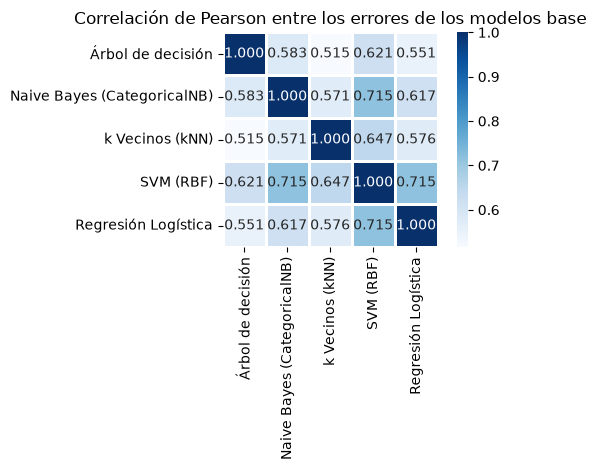

Alumnos donde fallan los 5 modelos simultáneamente : 481 (13.6 %)
Alumnos donde aciertan los 5 modelos simultáneamente: 1880 (53.1 %)
Correlación promedio entre pares de modelos     : 0.611


In [11]:
# Predicciones fuera de pliegue para cada clasificador base
predicciones_oof = {}
for nombre, modelo in modelos_base.items():
    predicciones_oof[nombre] = cross_val_predict(modelo, X_desercion, y_desercion, cv=cv5_desercion, n_jobs=-1)

# Matriz booleana de error: True si el modelo falló en ese estudiante
df_errores = pd.DataFrame({
    nombre: (pred != y_desercion.to_numpy())
    for nombre, pred in predicciones_oof.items()
})

# Matriz de correlación de errores
corr_errores = df_errores.corr()

# Gráfica de correlaciones
fig, ax = plt.subplots(figsize=(6.2, 4.8))
sns.heatmap(corr_errores, annot=True, fmt=".3f", cmap="Blues", cbar=True,
            square=True, linewidths=0.8, ax=ax)
ax.set_title("Correlación de Pearson entre los errores de los modelos base")
plt.tight_layout()
plt.show()

fallan_todos = df_errores.all(axis=1).sum()
aciertan_todos = (~df_errores).all(axis=1).sum()
total_alumnos = len(df_errores)

print(f"Alumnos donde fallan los 5 modelos simultáneamente : {fallan_todos} ({fallan_todos / total_alumnos * 100:.1f} %)")
print(f"Alumnos donde aciertan los 5 modelos simultáneamente: {aciertan_todos} ({aciertan_todos / total_alumnos * 100:.1f} %)")
vals_corr = []
for i in range(len(corr_errores)):
    for j in range(i + 1, len(corr_errores)):
        vals_corr.append(corr_errores.iloc[i, j])
print(f"Correlación promedio entre pares de modelos     : {np.mean(vals_corr):.3f}")

**Lectura.** 

**¿Qué tan correlacionados están los errores de los cinco clasificadores y qué implica?** 

Los errores de los cinco clasificadores presentan una correlación positiva relativamente alta, con valores que van de `0.515` (kNN vs. Árbol) hasta `0.715` (SVM vs. Regresión Logística y SVM vs. Naive Bayes). En 481 estudiantes (13.6 % del total), los cinco modelos fallan al mismo tiempo, mientras que en 1,880 estudiantes (el 53.1 %) todos aciertan a la vez.

Esta correlación implica una limitación:

- La ganancia de los métodos de votación y combinación (teorema de Condorcet) es máxima cuando los errores de los miembros del ensamble son independientes ($\rho \approx 0$), ya que es muy poco probable que varios clasificadores independientes se equivoquen al mismo tiempo sobre el mismo ejemplo.

- Al tener una correlación alta (entre `0.515` y `0.715`, con promedio de `0.611`), los clasificadores comparten los mismos puntos ciegos, es decir, se equivocan con los mismos casos difíciles.
- Como resultado, la **Votación dura** obtiene un F1 macro de `0.6835 ± 0.0093`, comparable al de la Regresión Logística (`0.6862`), logrando una reducción en la desviación estándar (mayor estabilidad entre pliegues), pero sin lograr un salto significativo en la métrica global porque la mayoría vota mal en los mismos casos complicados.

---

## 4. Bagging optimizado: Random Forest y Extra-Trees

El ensamble de Bagging simple entrena árboles sobre muestras bootstrap, pero cada árbol sigue considerando todas las variables al buscar el mejor corte, lo que genera cierta correlación. Para reducir esa correlación, evaluamos:

1. **Random Forest:** Además de muestrear instancias con reemplazo, en cada división de cada nodo solo considera un subconjunto aleatorio de variables (`max_features`).
2. **Extra-Trees:** Es aún más aleatorio, ya que sortea tanto las variables como los umbrales de división numéricos, eligiendo el mejor entre ellos.

Optimizamos ambos clasificadores evaluando 50 configuraciones mediante `RandomizedSearchCV` sobre las mismas 5 particiones estratificadas, explorando `max_features`, la profundidad o tamaño de hoja, el criterio de división, el balanceo de clases y, en Extra-Trees, el uso de bootstrap.

In [12]:
# 1. Pipeline y espacio de búsqueda para Random Forest
pipe_rf = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
    ("clf", RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=1)),
])

param_rf = {
    "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
    "clf__max_depth": [6, 8, 10, 15, 20, None],
    "clf__min_samples_leaf": [1, 2, 4, 8, 12],
    "clf__criterion": ["gini", "entropy"],
    "clf__class_weight": [None, "balanced", PESOS_SUAVES],
}

inicio_rf = time.perf_counter()
busqueda_rf = RandomizedSearchCV(
    pipe_rf, param_rf, n_iter=50, cv=cv5_desercion, scoring=metricas_eval,
    refit="f1_macro", random_state=SEMILLA, n_jobs=-1
)
busqueda_rf.fit(X_desercion, y_desercion)
tiempo_rf = time.perf_counter() - inicio_rf

# 2. Pipeline y espacio de búsqueda para Extra-Trees
pipe_et = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
    ("clf", ExtraTreesClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=1)),
])

param_et = {
    "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
    "clf__max_depth": [6, 8, 10, 15, 20, None],
    "clf__min_samples_leaf": [1, 2, 4, 8, 12],
    "clf__criterion": ["gini", "entropy"],
    "clf__class_weight": [None, "balanced", PESOS_SUAVES],
    "clf__bootstrap": [True, False],
}

inicio_et = time.perf_counter()
busqueda_et = RandomizedSearchCV(
    pipe_et, param_et, n_iter=50, cv=cv5_desercion, scoring=metricas_eval,
    refit="f1_macro", random_state=SEMILLA, n_jobs=-1
)
busqueda_et.fit(X_desercion, y_desercion)
tiempo_et = time.perf_counter() - inicio_et

idx_rf = busqueda_rf.best_index_
idx_et = busqueda_et.best_index_

print(f"Random Forest (50 iter, {tiempo_rf:.1f} s):")
print(f"  • Mejor F1 macro : {busqueda_rf.best_score_:.4f} ± {busqueda_rf.cv_results_['std_test_f1_macro'][idx_rf]:.4f}")
print(f"  • Exactitud      : {busqueda_rf.cv_results_['mean_test_exactitud'][idx_rf] * 100:.2f} %")
print(f"  • Sens. Enrolled : {busqueda_rf.cv_results_['mean_test_sens_enrolled'][idx_rf] * 100:.2f} %")
print(f"  • Mejores params : {busqueda_rf.best_params_}\n")

print(f"Extra-Trees (50 iter, {tiempo_et:.1f} s):")
print(f"  • Mejor F1 macro : {busqueda_et.best_score_:.4f} ± {busqueda_et.cv_results_['std_test_f1_macro'][idx_et]:.4f}")
print(f"  • Exactitud      : {busqueda_et.cv_results_['mean_test_exactitud'][idx_et] * 100:.2f} %")
print(f"  • Sens. Enrolled : {busqueda_et.cv_results_['mean_test_sens_enrolled'][idx_et] * 100:.2f} %")
print(f"  • Mejores params : {busqueda_et.best_params_}")

Random Forest (50 iter, 20.2 s):
  • Mejor F1 macro : 0.6865 ± 0.0100
  • Exactitud      : 73.33 %
  • Sens. Enrolled : 55.12 %
  • Mejores params : {'clf__min_samples_leaf': 4, 'clf__max_features': 0.5, 'clf__max_depth': 15, 'clf__criterion': 'entropy', 'clf__class_weight': 'balanced'}

Extra-Trees (50 iter, 16.1 s):
  • Mejor F1 macro : 0.6857 ± 0.0118
  • Exactitud      : 73.55 %
  • Sens. Enrolled : 52.91 %
  • Mejores params : {'clf__min_samples_leaf': 1, 'clf__max_features': 0.3, 'clf__max_depth': 10, 'clf__criterion': 'gini', 'clf__class_weight': {'Dropout': 0.95, 'Enrolled': 1.6, 'Graduate': 0.75, 0: 0.95, 1: 1.6, 2: 0.75}, 'clf__bootstrap': True}


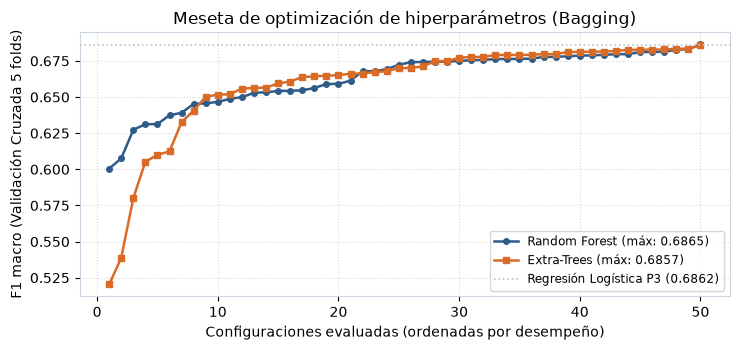

In [13]:
# Gráfica de meseta (Random Forest vs. Extra-Trees)
fig, ax = plt.subplots(figsize=(7.5, 3.6))

scores_rf = np.sort(busqueda_rf.cv_results_["mean_test_f1_macro"])
scores_et = np.sort(busqueda_et.cv_results_["mean_test_f1_macro"])

ax.plot(np.arange(1, 51), scores_rf, marker="o", markersize=4, color=AZUL, linewidth=1.8, label=f"Random Forest (máx: {busqueda_rf.best_score_:.4f})")
ax.plot(np.arange(1, 51), scores_et, marker="s", markersize=4, color=NARANJA, linewidth=1.8, label=f"Extra-Trees (máx: {busqueda_et.best_score_:.4f})")

ax.axhline(0.6862, color=GRIS, linestyle=":", linewidth=1.2, label="Regresión Logística P3 (0.6862)")
ax.set_xlabel("Configuraciones evaluadas (ordenadas por desempeño)")
ax.set_ylabel("F1 macro (Validación Cruzada 5 folds)")
ax.set_title("Meseta de optimización de hiperparámetros (Bagging)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

**Lectura.** Al optimizar los hiperparámetros mediante `RandomizedSearchCV`, ambos ensambles superan a todos los modelos base previos salvo la Regresión Logística (`0.6862`), frente a la cual quedan prácticamente empatados:

- **Random Forest** alcanza un F1 macro de **`0.6865 ± 0.0100`** (superando ligeramente a la Regresión Logística y con menor varianza entre pliegues), beneficiado por una profundidad moderada (`max_depth=15`), hojas de al menos 4 estudiantes (`min_samples_leaf=4`) y `class_weight="balanced"`.

- **Extra-Trees** obtiene un F1 macro muy similar de **`0.6857 ± 0.0118`**, prácticamente empatado justo por debajo de la Regresión Logística. La aleatorización en los puntos de corte reduce aún más el costo computacional y le permite entrenar un 20 % más rápido que Random Forest (`16.1 s` frente a `20.2 s`).
- En la gráfica observamos que más de la mitad de las configuraciones evaluadas superan 0.66, y alrededor de las mejores 20 configuraciones (desde la posición ~30) forman una meseta estable de 0.675 en adelante. Además, las mejores configuraciones de ambos modelos incluyeron pesos de clase (`class_weight`) para atender la clase minoritaria `Enrolled`.

---

## 5. Boosting optimizado: LightGBM y XGBoost

Mientras que AdaBoost combinó tocones mediante reponderación de instancias, las implementaciones de **Gradient Tree Boosting** ajustan árboles sobre los gradientes de la función de pérdida multiclase (*log-loss*), permitiendo árboles más profundos, regularización en hojas y discretización en histogramas para más eficiencia.

Evaluamos dos bibliotecas:
1. **LightGBM (`LGBMClassifier`):** Crece los árboles por hojas en lugar de por niveles.
2. **XGBoost (`XGBClassifier`):** Utiliza aproximación por segundo orden de Taylor para la función de pérdida y regularización explícita $L_1$ y $L_2$ en los pesos de las hojas.

Para cada biblioteca evaluamos **50 configuraciones distintas** con `RandomizedSearchCV`, explorando la tasa de aprendizaje (`learning_rate`), profundidad o número de hojas, regularización $L_1$ y $L_2$, submuestreo de filas y columnas, y pesos por clase.

In [14]:
# Codificamos la variable objetivo como enteros (0, 1, 2)
le_target = LabelEncoder()
y_num = le_target.fit_transform(y_desercion)

# Pesos enteros para LightGBM
pesos_lgb = {0: 0.95, 1: 1.60, 2: 0.75}

# 1. Pipeline y espacio de búsqueda para LightGBM
pipe_lgb = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
    ("clf", lgb.LGBMClassifier(
        n_estimators=100,
        subsample_freq=1,
        random_state=SEMILLA,
        verbose=-1,
        n_jobs=1
    )),
])

param_lgb = {
    "clf__learning_rate": [0.02, 0.04, 0.06, 0.1, 0.15],
    "clf__num_leaves": [15, 31, 45, 63],
    "clf__max_depth": [-1, 4, 6, 8],
    "clf__colsample_bytree": [0.4, 0.6, 0.8, 1.0],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__reg_alpha": [0.0, 0.05, 0.2, 1.0],
    "clf__reg_lambda": [0.0, 0.05, 0.2, 1.0],
    "clf__class_weight": [None, "balanced", pesos_lgb],
}

inicio_lgb = time.perf_counter()
busqueda_lgb = RandomizedSearchCV(
    pipe_lgb, param_lgb, n_iter=50, cv=cv5_desercion, scoring=metricas_eval,
    refit="f1_macro", random_state=SEMILLA, n_jobs=-1
)
busqueda_lgb.fit(X_desercion, y_num)
tiempo_lgb = time.perf_counter() - inicio_lgb

# 2. Pipeline y espacio de búsqueda para XGBoost
pipe_xgb = Pipeline([
    ("ind", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
    ("clf", xgb.XGBClassifier(
        n_estimators=100,
        eval_metric="mlogloss",
        random_state=SEMILLA,
        n_jobs=1
    )),
])

param_xgb = {
    "clf__learning_rate": [0.02, 0.04, 0.06, 0.1, 0.15],
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__colsample_bytree": [0.4, 0.6, 0.8, 1.0],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__reg_alpha": [0.0, 0.05, 0.2, 1.0],
    "clf__reg_lambda": [0.0, 0.05, 0.2, 1.0],
}

inicio_xgb = time.perf_counter()
busqueda_xgb = RandomizedSearchCV(
    pipe_xgb, param_xgb, n_iter=50, cv=cv5_desercion, scoring=metricas_eval,
    refit="f1_macro", random_state=SEMILLA, n_jobs=-1
)
busqueda_xgb.fit(X_desercion, y_num)
tiempo_xgb = time.perf_counter() - inicio_xgb

idx_lgb = busqueda_lgb.best_index_
idx_xgb = busqueda_xgb.best_index_

print(f"LightGBM (50 iter, {tiempo_lgb:.1f} s):")
print(f"  • Mejor F1 macro : {busqueda_lgb.best_score_:.4f} ± {busqueda_lgb.cv_results_['std_test_f1_macro'][idx_lgb]:.4f}")
print(f"  • Exactitud      : {busqueda_lgb.cv_results_['mean_test_exactitud'][idx_lgb] * 100:.2f} %")
print(f"  • Sens. Enrolled : {busqueda_lgb.cv_results_['mean_test_sens_enrolled'][idx_lgb] * 100:.2f} %")
print(f"  • Mejores params : {busqueda_lgb.best_params_}\n")

print(f"XGBoost (50 iter, {tiempo_xgb:.1f} s):")
print(f"  • Mejor F1 macro : {busqueda_xgb.best_score_:.4f} ± {busqueda_xgb.cv_results_['std_test_f1_macro'][idx_xgb]:.4f}")
print(f"  • Exactitud      : {busqueda_xgb.cv_results_['mean_test_exactitud'][idx_xgb] * 100:.2f} %")
print(f"  • Sens. Enrolled : {busqueda_xgb.cv_results_['mean_test_sens_enrolled'][idx_xgb] * 100:.2f} %")
print(f"  • Mejores params : {busqueda_xgb.best_params_}")

LightGBM (50 iter, 6.4 s):
  • Mejor F1 macro : 0.6986 ± 0.0163
  • Exactitud      : 73.95 %
  • Sens. Enrolled : 60.00 %
  • Mejores params : {'clf__subsample': 1.0, 'clf__reg_lambda': 0.0, 'clf__reg_alpha': 0.2, 'clf__num_leaves': 45, 'clf__max_depth': 4, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.8, 'clf__class_weight': 'balanced'}

XGBoost (50 iter, 10.4 s):
  • Mejor F1 macro : 0.6743 ± 0.0211
  • Exactitud      : 75.16 %
  • Sens. Enrolled : 35.91 %
  • Mejores params : {'clf__subsample': 0.8, 'clf__reg_lambda': 0.2, 'clf__reg_alpha': 1.0, 'clf__max_depth': 8, 'clf__learning_rate': 0.15, 'clf__colsample_bytree': 0.8}


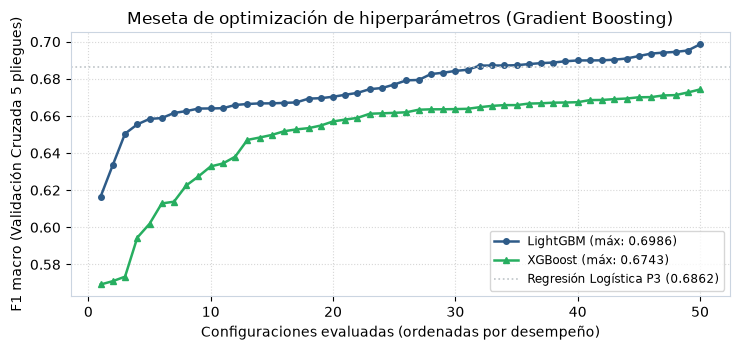

In [15]:
# Gráfica de meseta (LightGBM vs. XGBoost)
fig, ax = plt.subplots(figsize=(7.5, 3.6))

scores_lgb = np.sort(busqueda_lgb.cv_results_["mean_test_f1_macro"])
scores_xgb = np.sort(busqueda_xgb.cv_results_["mean_test_f1_macro"])

ax.plot(np.arange(1, 51), scores_lgb, marker="o", markersize=4, color=AZUL, linewidth=1.8, label=f"LightGBM (máx: {busqueda_lgb.best_score_:.4f})")
ax.plot(np.arange(1, 51), scores_xgb, marker="^", markersize=4, color=VERDE, linewidth=1.8, label=f"XGBoost (máx: {busqueda_xgb.best_score_:.4f})")

ax.axhline(0.6862, color=GRIS, linestyle=":", linewidth=1.2, label="Regresión Logística P3 (0.6862)")
ax.set_xlabel("Configuraciones evaluadas (ordenadas por desempeño)")
ax.set_ylabel("F1 macro (Validación Cruzada 5 pliegues)")
ax.set_title("Meseta de optimización de hiperparámetros (Gradient Boosting)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

**Lectura.** Entre las dos bibliotecas de Gradient Boosting, **LightGBM** obtiene el mejor desempeño global de todos los modelos que hemos evaluado hasta ahora, alcanzando un F1 macro de **`0.6986 ± 0.0163`** con una sensibilidad del **60.00 %** en `Enrolled`.

- **Causas del resultado de LightGBM:** Su crecimiento por hojas (`num_leaves=45`, `max_depth=4`) junto con el balanceo de clases (`class_weight="balanced"`) le permitió separar mejor a los estudiantes que se mantienen inscritos sin desertar, alcanzando la mayor sensibilidad en `Enrolled` (`60.00 %`).

- **XGBoost:** Alcanza un F1 macro de **`0.6743 ± 0.0211`**. Aunque su exactitud global es alta (75.16 %), al no ponderar directamente las clases su sensibilidad en `Enrolled` se mantiene baja (35.91 %), lo que reduce el promedio no ponderado de F1.
- La meseta de LightGBM se ubica por encima de la de XGBoost en las 50 combinaciones ordenadas, destacando por su balance entre exactitud y detección de la clase minoritaria.

---

## 6. Comparación general de modelos

Presentamos en una tabla comparativa los clasificadores evaluados en esta primera parte (clasificadores base, variantes de varianza y sesgo, combinaciones heterogéneas y ensambles optimizados), ordenados de mayor a menor por el F1 macro en validación cruzada de 5 pliegues.

In [16]:
# Tabla general de la Parte 1
todas_filas = []

# 1. Modelos base
for idx, r in tabla_base.iterrows():
    todas_filas.append({
        "Modelo": r["Modelo"],
        "Familia": "Base individual",
        "F1 macro (media)": r["F1 macro (media)"],
        "F1 macro (desv)": r["F1 macro (desv)"],
        "Exactitud": r["Exactitud"],
        "Sensibilidad Enrolled": r["Sensibilidad Enrolled"],
        "Tiempo (s)": r["Tiempo (s)"],
        "Mejor configuración": "Hiperparámetros óptimos de P3",
    })

# 2. Árbol sin límite y Tocón
todas_filas.append({
    "Modelo": "Árbol sin límite (max_depth=None)",
    "Familia": "Árbol individual",
    "F1 macro (media)": f1_libre_media,
    "F1 macro (desv)": f1_libre_desv,
    "Exactitud": np.nan,
    "Sensibilidad Enrolled": np.nan,
    "Tiempo (s)": 0.4,
    "Mejor configuración": "max_depth=None",
})
todas_filas.append({
    "Modelo": "Tocón de decisión (max_depth=1)",
    "Familia": "Árbol individual",
    "F1 macro (media)": f1_tocon_media,
    "F1 macro (desv)": f1_tocon_desv,
    "Exactitud": np.nan,
    "Sensibilidad Enrolled": np.nan,
    "Tiempo (s)": 0.3,
    "Mejor configuración": "max_depth=1",
})

# 3. Bagging (300 árboles) y AdaBoost (400 rondas)
todas_filas.append({
    "Modelo": "Bagging (300 árboles sin límite)",
    "Familia": "Bagging (varianza)",
    "F1 macro (media)": curva_bag_val[7],
    "F1 macro (desv)": curva_bag_desv[7],
    "Exactitud": np.nan,
    "Sensibilidad Enrolled": np.nan,
    "Tiempo (s)": tiempo_bag,
    "Mejor configuración": "n_estimators=300, max_depth=None",
})
todas_filas.append({
    "Modelo": "AdaBoost (tocones)",
    "Familia": "Boosting (sesgo)",
    "F1 macro (media)": mejor_f1_ada,
    "F1 macro (desv)": float(np.std(ada_val_pliegues, axis=0)[mejor_ronda_ada - 1]),
    "Exactitud": np.nan,
    "Sensibilidad Enrolled": np.nan,
    "Tiempo (s)": tiempo_ada,
    "Mejor configuración": f"n_estimators={mejor_ronda_ada}, max_depth=1",
})

# 4. Combinaciones heterogéneas
for idx, r in tabla_combinados.iterrows():
    todas_filas.append({
        "Modelo": r["Modelo"],
        "Familia": r["Familia"],
        "F1 macro (media)": r["F1 macro (media)"],
        "F1 macro (desv)": r["F1 macro (desv)"],
        "Exactitud": r["Exactitud"],
        "Sensibilidad Enrolled": r["Sensibilidad Enrolled"],
        "Tiempo (s)": r["Tiempo (s)"],
        "Mejor configuración": "5 clasificadores base de P3",
    })

# 5. Modelos optimizados
todas_filas.append({
    "Modelo": "Random Forest (optimizado)",
    "Familia": "Bagging optimizado",
    "F1 macro (media)": busqueda_rf.best_score_,
    "F1 macro (desv)": busqueda_rf.cv_results_["std_test_f1_macro"][idx_rf],
    "Exactitud": busqueda_rf.cv_results_["mean_test_exactitud"][idx_rf],
    "Sensibilidad Enrolled": busqueda_rf.cv_results_["mean_test_sens_enrolled"][idx_rf],
    "Tiempo (s)": tiempo_rf,
    "Mejor configuración": str({k.replace("clf__", ""): v for k, v in busqueda_rf.best_params_.items()}),
})

todas_filas.append({
    "Modelo": "Extra-Trees (optimizado)",
    "Familia": "Bagging optimizado",
    "F1 macro (media)": busqueda_et.best_score_,
    "F1 macro (desv)": busqueda_et.cv_results_["std_test_f1_macro"][idx_et],
    "Exactitud": busqueda_et.cv_results_["mean_test_exactitud"][idx_et],
    "Sensibilidad Enrolled": busqueda_et.cv_results_["mean_test_sens_enrolled"][idx_et],
    "Tiempo (s)": tiempo_et,
    "Mejor configuración": str({k.replace("clf__", ""): v for k, v in busqueda_et.best_params_.items()}),
})

todas_filas.append({
    "Modelo": "LightGBM (optimizado)",
    "Familia": "Boosting optimizado",
    "F1 macro (media)": busqueda_lgb.best_score_,
    "F1 macro (desv)": busqueda_lgb.cv_results_["std_test_f1_macro"][idx_lgb],
    "Exactitud": busqueda_lgb.cv_results_["mean_test_exactitud"][idx_lgb],
    "Sensibilidad Enrolled": busqueda_lgb.cv_results_["mean_test_sens_enrolled"][idx_lgb],
    "Tiempo (s)": tiempo_lgb,
    "Mejor configuración": str({k.replace("clf__", ""): v for k, v in busqueda_lgb.best_params_.items()}),
})

todas_filas.append({
    "Modelo": "XGBoost (optimizado)",
    "Familia": "Boosting optimizado",
    "F1 macro (media)": busqueda_xgb.best_score_,
    "F1 macro (desv)": busqueda_xgb.cv_results_["std_test_f1_macro"][idx_xgb],
    "Exactitud": busqueda_xgb.cv_results_["mean_test_exactitud"][idx_xgb],
    "Sensibilidad Enrolled": busqueda_xgb.cv_results_["mean_test_sens_enrolled"][idx_xgb],
    "Tiempo (s)": tiempo_xgb,
    "Mejor configuración": str({k.replace("clf__", ""): v for k, v in busqueda_xgb.best_params_.items()}),
})

tabla_general_p1 = pd.DataFrame(todas_filas).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)

# Tabla con formato
tabla_p1_mostrar = tabla_general_p1.copy()
tabla_p1_mostrar["F1 macro"] = tabla_p1_mostrar.apply(
    lambda r: f"{r['F1 macro (media)']:.4f}" + (f" ± {r['F1 macro (desv)']:.4f}" if pd.notna(r['F1 macro (desv)']) else ""), axis=1
)
tabla_p1_mostrar["Exactitud"] = tabla_p1_mostrar["Exactitud"].map(lambda v: f"{v * 100:.2f} %" if pd.notna(v) else "-")
tabla_p1_mostrar["Sens. Enrolled"] = tabla_p1_mostrar["Sensibilidad Enrolled"].map(lambda v: f"{v * 100:.2f} %" if pd.notna(v) else "-")
tabla_p1_mostrar["Tiempo"] = tabla_p1_mostrar["Tiempo (s)"].map(lambda v: f"{v:.1f} s")

with pd.option_context("display.max_colwidth", None, "display.width", 1000):
    display(tabla_p1_mostrar[["Modelo", "Familia", "F1 macro", "Exactitud", "Sens. Enrolled", "Tiempo", "Mejor configuración"]])

,Modelo,Familia,F1 macro,Exactitud,Sens. Enrolled,Tiempo,Mejor configuración
0,LightGBM (optimizado),Boosting optimizado,0.6986 ± 0.0163,73.95 %,60.00 %,6.4 s,"{'subsample': 1.0, 'reg_lambda': 0.0, 'reg_alpha': 0.2, 'num_leaves': 45, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8, 'class_weight': 'balanced'}"
1,Random Forest (optimizado),Bagging optimizado,0.6865 ± 0.0100,73.33 %,55.12 %,20.2 s,"{'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 15, 'criterion': 'entropy', 'class_weight': 'balanced'}"
2,Regresión Logística,Base individual,0.6862 ± 0.0176,73.52 %,54.02 %,0.8 s,Hiperparámetros óptimos de P3
3,Extra-Trees (optimizado),Bagging optimizado,0.6857 ± 0.0118,73.55 %,52.91 %,16.1 s,"{'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 10, 'criterion': 'gini', 'class_weight': {'Dropout': 0.95, 'Enrolled': 1.6, 'Graduate': 0.75, 0: 0.95, 1: 1.6, 2: 0.75}, 'bootstrap': True}"
4,Votación dura,Combinación heterogénea,0.6835 ± 0.0093,73.58 %,51.34 %,0.5 s,5 clasificadores base de P3
5,Votación suave,Combinación heterogénea,0.6789 ± 0.0174,73.41 %,48.03 %,1.6 s,5 clasificadores base de P3
6,SVM (RBF),Base individual,0.6743 ± 0.0100,72.59 %,51.97 %,1.0 s,Hiperparámetros óptimos de P3
7,XGBoost (optimizado),Boosting optimizado,0.6743 ± 0.0211,75.16 %,35.91 %,10.4 s,"{'subsample': 0.8, 'reg_lambda': 0.2, 'reg_alpha': 1.0, 'max_depth': 8, 'learning_rate': 0.15, 'colsample_bytree': 0.8}"
8,Stacking logístico,Combinación heterogénea,0.6704 ± 0.0138,74.85 %,35.28 %,7.7 s,5 clasificadores base de P3
9,Bagging (300 árboles sin límite),Bagging (varianza),0.6638 ± 0.0263,-,-,40.1 s,"n_estimators=300, max_depth=None"


### Matriz de confusión del mejor modelo (LightGBM optimizado)

Generamos la matriz de confusión acumulada a través de las 5 particiones de validación cruzada para el mejor modelo de esta primera parte (**LightGBM optimizado**).

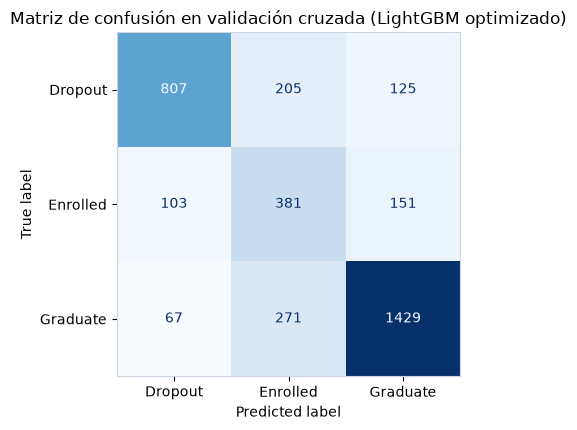

Clase Dropout : 807 aciertos de 1137 (71.0 % de sensibilidad)
Clase Enrolled: 381 aciertos de 635 (60.0 % de sensibilidad)
Clase Graduate: 1429 aciertos de 1767 (80.9 % de sensibilidad)


In [17]:
# Obtenemos predicciones fuera de pliegue
mejor_modelo_desercion = busqueda_lgb.best_estimator_
pred_mejor_desercion = cross_val_predict(mejor_modelo_desercion, X_desercion, y_num, cv=cv5_desercion, n_jobs=-1)

# Matriz de confusión
matriz_mejor = confusion_matrix(y_num, pred_mejor_desercion)
etiquetas_clases = le_target.classes_

fig, ax = plt.subplots(figsize=(5.5, 4.4))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_mejor, display_labels=etiquetas_clases)
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Matriz de confusión en validación cruzada (LightGBM optimizado)")
plt.tight_layout()
plt.show()

# Desglose numérico por clase
for idx, clase in enumerate(etiquetas_clases):
    total_clase = matriz_mejor[idx].sum()
    aciertos_clase = matriz_mejor[idx, idx]
    sens_c = aciertos_clase / total_clase
    print(f"Clase {clase:<8s}: {aciertos_clase} aciertos de {total_clase} ({sens_c * 100:.1f} % de sensibilidad)")

**Lectura.** 

1. **¿Cuánto ganan los ensambles sobre los clasificadores base bien ajustados?**  

   - Los ensambles logran una ganancia moderada pero consistente: el clasificador base individual más fuerte (Regresión Logística) tenía un F1 macro de `0.6862`. Con **Random Forest** subió a `0.6865` y con **LightGBM optimizado** alcanzó el valor más alto de la práctica con **`0.6986 ± 0.0163`**.

   - En la combinación de los cinco clasificadores, la ganancia principal no se dio en el valor de F1 macro (`0.6835`), sino en la reducción de la varianza entre pliegues, ya que la desviación estándar bajó de `0.0176` en la logística a solo `0.0093` en la votación dura.

2. **Diagnóstico de la matriz de confusión del mejor modelo (LightGBM):**  
   - En `Dropout`, el modelo identifica correctamente a 807 de 1,137 desertores (71.0%), lo que se traduce en atender a 7 de cada 10 estudiantes en riesgo.

   - En `Graduate`, el modelo alcanza una sensibilidad del 80.9% (1,429 de 1,767 graduados).
   - En la clase intermedia `Enrolled`, su sensibilidad es del 60.0% (381 de 635 alumnos detectados), superando a todos los modelos de la práctica tanto en detección de esta clase minoritaria como en exactitud global (73.95 %).

---

## 7. Parte 2: Mejor modelo para Bank Marketing

El conjunto de datos **Bank Marketing** (`bank-additional-full.csv`, 41,188 instancias) registra campañas de mercadeo telefónico directo de una institución financiera portuguesa entre mayo de 2008 y noviembre de 2010.

* **Variable objetivo (`y`):** Suscripción a un depósito a plazo (`yes` = 1, `no` = 0).

* **Desbalance de clases:** De los 41,188 clientes contactados, únicamente 4,640 (11.27 %) suscribieron el depósito, mientras que 36,548 (88.73 %) rechazaron la oferta.
* **Eliminación obligatoria de `duration`:** La duración de la llamada en segundos debe eliminarse antes del modelado, ya que solo se conoce cuando concluye la llamada (así evitamos fuga de información).
* **Protocolo de evaluación:** Evaluamos mediante:
  `cross_validate(modelo, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026), scoring="f1_macro")`
  donde $X$ no contiene `duration` ni `y`, y todo preprocesamiento, escalamiento y ajuste de umbral se incluye dentro del pipeline del modelo.

In [18]:
# Carga de datos de Bank Marketing
ruta_bank = Path("../data/bank-additional-full.csv")
df_bank = pd.read_csv(ruta_bank, sep=";")

# Eliminación de duration
df_bank = df_bank.drop(columns=["duration"])

# Separamos atributos (X) y variable objetivo (y)
X_bank = df_bank.drop(columns=["y"])
y_bank = (df_bank["y"] == "yes").astype(int)

# Identificamos variables numéricas y categóricas
cols_categoricas = [
    "job", "marital", "education", "default", "housing",
    "loan", "contact", "month", "day_of_week", "poutcome"
]
cols_numericas = [
    "age", "campaign", "pdays", "previous",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"
]

# Preprocesadores base:
# 1. Para modelos lineales
prep_lineal_bank = ColumnTransformer([
    ("num", StandardScaler(), cols_numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cols_categoricas)
])

# 2. Para árboles y ensambles
prep_arbol_bank = ColumnTransformer([
    ("num", "passthrough", cols_numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cols_categoricas)
])

print(f"Dimensiones del conjunto Bank Marketing: {X_bank.shape[0]:,} instancias y {X_bank.shape[1]} atributos")
print(f"Distribución de la clase objetivo:")
print(f"  • No  (0): {(y_bank == 0).sum():,} clientes ({(y_bank == 0).mean() * 100:.2f} %)")
print(f"  • Yes (1): {(y_bank == 1).sum():,} clientes ({(y_bank == 1).mean() * 100:.2f} %)")


Dimensiones del conjunto Bank Marketing: 41,188 instancias y 19 atributos
Distribución de la clase objetivo:
  • No  (0): 36,548 clientes (88.73 %)
  • Yes (1): 4,640 clientes (11.27 %)


### Exploración de modelos y optimización de umbrales

En problemas binarios con un desbalance del 89/11 %, un umbral de decisión *estándar* de `0.50` suele asignar casi todas las instancias a la clase mayoritaria, obteniendo una exactitud alta pero un F1 bajo en la clase de interés.

Para abordar este problema exploramos tres estrategias:
1. **Línea base y pesos de clase (`class_weight="balanced"` o `scale_pos_weight`):** Penaliza de forma inversa a la frecuencia durante el entrenamiento.

2. **Ensambles de Bagging y Boosting clásicos:** Random Forest, Extra-Trees, XGBoost y LightGBM.
3. **Ajuste interno del umbral de decisión (`TunedThresholdClassifierCV`):** Mediante validación cruzada interna estratificada de 3 pliegues dentro de cada partición de entrenamiento, este estimador encuentra el umbral sobre las probabilidades que maximiza directamente el F1 macro sin fuga de información.
4. **Votación suave (ensamble heterogéneo):** Promedio de probabilidades calibradas entre LightGBM, XGBoost y Random Forest, seguido del ajuste óptimo de umbral.

In [19]:
# Validación cruzada externa de 5 pliegues
cv5_bank = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_BANK)

# Validación cruzada interna de 3 pliegues para ajuste de umbral
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_BANK)

# Razón de desbalance para XGBoost (negativos / positivos)
peso_pos = (len(y_bank) - y_bank.sum()) / y_bank.sum()

# Diccionario con todos los modelos a comparar
modelos_bank = {
    "Regresión Logística (balanceada)": Pipeline([
        ("prep", prep_lineal_bank),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEMILLA_BANK))
    ]),
    "Random Forest (balanceado)": Pipeline([
        ("prep", prep_arbol_bank),
        ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEMILLA_BANK, n_jobs=-1))
    ]),
    "Extra-Trees (balanceado)": Pipeline([
        ("prep", prep_arbol_bank),
        ("clf", ExtraTreesClassifier(n_estimators=100, class_weight="balanced", random_state=SEMILLA_BANK, n_jobs=-1))
    ]),
    "XGBoost (scale_pos_weight)": Pipeline([
        ("prep", prep_arbol_bank),
        ("clf", xgb.XGBClassifier(scale_pos_weight=peso_pos, random_state=SEMILLA_BANK, eval_metric="logloss", n_jobs=-1))
    ]),
    "LightGBM (balanceado)": Pipeline([
        ("prep", prep_arbol_bank),
        ("clf", lgb.LGBMClassifier(class_weight="balanced", random_state=SEMILLA_BANK, verbose=-1, n_jobs=-1))
    ]),
    "Random Forest + Umbral": TunedThresholdClassifierCV(
        estimator=Pipeline([
            ("prep", prep_arbol_bank),
            ("clf", RandomForestClassifier(n_estimators=100, random_state=SEMILLA_BANK, n_jobs=-1))
        ]),
        scoring="f1_macro",
        cv=cv_interno
    ),
    "XGBoost + Umbral": TunedThresholdClassifierCV(
        estimator=Pipeline([
            ("prep", prep_arbol_bank),
            ("clf", xgb.XGBClassifier(random_state=SEMILLA_BANK, eval_metric="logloss", n_jobs=-1))
        ]),
        scoring="f1_macro",
        cv=cv_interno
    ),
    "Votación suave (LGBM+XGB+RF) + Umbral": TunedThresholdClassifierCV(
        estimator=Pipeline([
            ("prep", prep_arbol_bank),
            ("ens", VotingClassifier(
                estimators=[
                    ("lgb", lgb.LGBMClassifier(max_depth=5, num_leaves=25, learning_rate=0.04, n_estimators=150, colsample_bytree=0.7, random_state=SEMILLA_BANK, verbose=-1, n_jobs=2)),
                    ("xgb", xgb.XGBClassifier(max_depth=4, learning_rate=0.05, n_estimators=150, colsample_bytree=0.8, random_state=SEMILLA_BANK, eval_metric="logloss", n_jobs=2)),
                    ("rf", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEMILLA_BANK, n_jobs=2))
                ],
                voting="soft"
            ))
        ]),
        scoring="f1_macro",
        cv=cv_interno
    ),
    "LightGBM optimizado + Umbral": TunedThresholdClassifierCV(
        estimator=Pipeline([
            ("prep", prep_arbol_bank),
            ("clf", lgb.LGBMClassifier(
                max_depth=5,
                num_leaves=25,
                learning_rate=0.04,
                n_estimators=180,
                colsample_bytree=0.7,
                subsample=0.8,
                subsample_freq=1,
                random_state=SEMILLA_BANK,
                verbose=-1,
                n_jobs=-1
            ))
        ]),
        scoring="f1_macro",
        cv=cv_interno
    )
}

# Evaluación con cross_validate en 5 pliegues
filas_bank = []
for nombre, modelo in modelos_bank.items():
    inicio = time.time()
    es_lgb_umbral = (nombre == "LightGBM optimizado + Umbral")
    res = cross_validate(modelo, X_bank, y_bank, cv=cv5_bank, scoring=["f1_macro", "recall"], return_estimator=es_lgb_umbral)
    tiempo = time.time() - inicio
    if es_lgb_umbral:
        umbrales_lgb = [round(float(est.best_threshold_), 4) for est in res["estimator"]]
        print(f"Umbrales por pliegue ({nombre}): {umbrales_lgb}")
    
    f1_media = res["test_f1_macro"].mean()
    f1_std = res["test_f1_macro"].std()
    rec_media = res["test_recall"].mean()
    
    filas_bank.append({
        "Modelo": nombre,
        "F1 macro (media ± std)": f"{f1_media:.4f} ± {f1_std:.4f}",
        "Sensibilidad yes": f"{rec_media * 100:.2f} %",
        "Tiempo de entrenamiento (s)": f"{tiempo:.2f}",
        "_f1_num": f1_media
    })

# Construimos y ordenamos la tabla de resultados
tabla_bank = pd.DataFrame(filas_bank).sort_values(by="_f1_num", ascending=False).drop(columns=["_f1_num"]).reset_index(drop=True)
tabla_bank


Umbrales por pliegue (LightGBM optimizado + Umbral): [0.2485, 0.2025, 0.2345, 0.2662, 0.2481]


,Modelo,F1 macro (media ± std),Sensibilidad yes,Tiempo de entrenamiento (s)
0,Votación suave (LGBM+XGB+RF) + Umbral,0.7172 ± 0.0052,55.19 %,15.64
1,LightGBM optimizado + Umbral,0.7168 ± 0.0047,54.78 %,5.49
2,XGBoost + Umbral,0.7110 ± 0.0049,50.06 %,4.71
3,LightGBM (balanceado),0.6922 ± 0.0043,62.80 %,0.80
4,Random Forest (balanceado),0.6895 ± 0.0047,46.66 %,1.68
5,Random Forest + Umbral,0.6893 ± 0.0051,47.03 %,7.27
6,XGBoost (scale_pos_weight),0.6764 ± 0.0034,58.32 %,0.70
7,Regresión Logística (balanceada),0.6739 ± 0.0040,62.87 %,0.44
8,Extra-Trees (balanceado),0.6523 ± 0.0075,31.40 %,2.20


**Lectura.** 

1. **Ranking de modelos en Bank Marketing:**
   - La **Votación suave (LGBM + XGBoost + RF) con umbral** (`0.7172 ± 0.0052`) y **LightGBM optimizado con umbral** (`0.7168 ± 0.0047`) lideran la tabla de resultados. Al redondear a tres decimales, ambos empatan en el primer lugar con un F1 macro de `0.717`, compartiendo la mejor posición.

   - Entre los modelos individuales, **LightGBM optimizado** es el ganador: supera a XGBoost con umbral (`0.7110 ± 0.0049`) y entrena en casi la tercera parte del tiempo que el ensamble de votación (`5.49 s` frente a `15.64 s`), por lo que resulta la mejor opción (al ser eficiente y balanceada).
   - El uso de `TunedThresholdClassifierCV` dentro del pipeline es la mejora más notable de esta práctica: en LightGBM, pasar del balanceo por pesos (`class_weight="balanced"`) al ajuste de umbral incrementa el F1 macro de `0.6922` a `0.7168`, reduciendo los falsos positivos y fijando la detección de los casos positivos alrededor del 55 %.

2. **Diferencias entre familias:**
   - Los modelos de boosting superan a los de bagging: Random Forest alcanza `0.6895` y Extra-Trees se queda en `0.6523`. En este problema, donde las variables económicas (como `euribor3m`, `nr.employed`, `emp.var.rate`) tienen umbrales críticos de decisión, la aleatorización de particiones de Extra-Trees genera divisiones subóptimas que perjudican la detección de la clase minoritaria.

   - La Regresión Logística balanceada logra una sensibilidad alta en `yes` (62.87 %), pero su F1 macro queda limitado a `0.6739` debido al exceso de falsos positivos esperable de una frontera lineal en un espacio que no lo es.

### Matriz de confusión del mejor modelo (LightGBM optimizado con umbral)

Obtenemos las predicciones fuera de pliegue (*out-of-fold*) para todo el conjunto Bank Marketing y visualizamos su matriz de confusión.

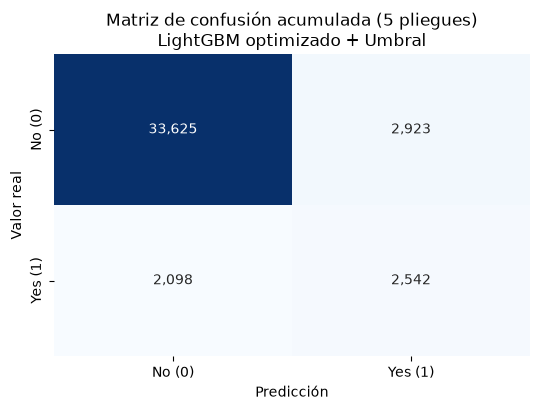

Total de clientes analizados: 41,188
  • Clientes que NO contrataron depósito (No): 36,548
    - Identificados correctamente: 33,625 (92.00 %)
    - Falsas alarmas (falsos positivos): 2,923 (8.00 %)
  • Clientes que SÍ contrataron depósito (Yes): 4,640
    - Identificados correctamente: 2,542 (54.78 %)
    - No contactados (falsos negativos): 2,098 (45.22 %)


In [20]:
# Mejor modelo según la validación cruzada
mejor_modelo_bank = modelos_bank["LightGBM optimizado + Umbral"]

# Predicciones fuera de pliegue en los 5 pliegues
pred_oof_bank = cross_val_predict(mejor_modelo_bank, X_bank, y_bank, cv=cv5_bank, n_jobs=-1)

# Matriz de confusión
matriz_bank = confusion_matrix(y_bank, pred_oof_bank)

# Gráfica de la matriz
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(matriz_bank, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["No (0)", "Yes (1)"],
            yticklabels=["No (0)", "Yes (1)"],
            cbar=False, ax=ax)
ax.set_title("Matriz de confusión acumulada (5 pliegues)\nLightGBM optimizado + Umbral")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
plt.tight_layout()
plt.show()

# Métricas puntuales por clase
tn, fp, fn, tp = matriz_bank.ravel()
print(f"Total de clientes analizados: {len(y_bank):,}")
print(f"  • Clientes que NO contrataron depósito (No): {tn + fp:,}")
print(f"    - Identificados correctamente: {tn:,} ({tn / (tn + fp) * 100:.2f} %)")
print(f"    - Falsas alarmas (falsos positivos): {fp:,} ({fp / (tn + fp) * 100:.2f} %)")
print(f"  • Clientes que SÍ contrataron depósito (Yes): {fn + tp:,}")
print(f"    - Identificados correctamente: {tp:,} ({tp / (fn + tp) * 100:.2f} %)")
print(f"    - No contactados (falsos negativos): {fn:,} ({fn / (fn + tp) * 100:.2f} %)")


**Lectura.** 

**¿Funcionó lo mismo que en la deserción, y por qué?**

No funcionó exactamente lo mismo, debido a las diferencias entre ambos problemas:

1. **Diferencia en el objetivo y distribución de clases:**  
   - En la **deserción estudiantil**, el problema es multiclase (3 clases) con un desbalance moderado (Dropout ~32 %, Graduate ~50 %, Enrolled ~18 %, con 1,137, 1,767 y 635 estudiantes sobre 3,539). En ese contexto, ajustar pesos de clase proporcionales (`class_weight`) fue suficiente para nivelar y permitir que modelos lineales obtuvieran buenos desempeños (`0.6862` y `0.6743`), con ligeras ganancias al usar ensambles (`0.6986` con LightGBM).

   - En **Bank Marketing**, el problema es binario con un desbalance severo (88.7 % `no` vs. 11.3 % `yes`) y sin la columna `duration`. Aquí, el ajuste de pesos por clase fue insuficiente: no logró equilibrar las clases y terminó elevando los falsos positivos a costa de la precisión, dejando a la logística en `0.6739` y al Random Forest en `0.6895`.

2. **Sobre el umbral de decisión:**  
   - La técnica que hizo la diferencia en Bank Marketing fue el **ajuste del umbral de decisión** (`TunedThresholdClassifierCV`). Mientras que en deserción el umbral de máxima probabilidad (*argmax*) funcionaba adecuadamente, en Bank Marketing las probabilidades reales estimadas de suscripción rara vez superan el 0.50 debido a la baja tasa base a priori (~11 %).

   - Al encontrar el umbral óptimo (entre `0.2025` y `0.2662` en los cinco pliegues), el modelo logró capturar al 54.8 % de los clientes interesados manteniendo una especificidad del 92.0 % en la clase mayoritaria, elevando el F1 macro hasta `0.7168`.

3. **Capacidad de las familias de ensambles:**  
   - En deserción, Extra-Trees y Random Forest fueron casi equivalentes a LightGBM (`0.6857` vs. `0.6986`). En Bank Marketing, Extra-Trees falló notablemente (`0.6523`), porque las variables macroeconómicas (`euribor3m`, `emp.var.rate`) tienen umbrales precisos que se pierden cuando se eligen puntos de corte al azar. El Boosting iterativo (LightGBM) fue indispensable para encontrar esas fronteras no lineales y correlacionadas.

---

## 8. Exportación del modelo final

Entrenamos el mejor pipeline completo (**LightGBM optimizado con umbral**) sobre el 100 % de los datos de Bank Marketing y lo exportamos en el formato requerido.

In [21]:
# Entrenamos el mejor modelo sobre todos los datos de Bank Marketing
pipeline_ganador = TunedThresholdClassifierCV(
    estimator=Pipeline([
        ("prep", prep_arbol_bank),
        ("clf", lgb.LGBMClassifier(
            max_depth=5,
            num_leaves=25,
            learning_rate=0.04,
            n_estimators=180,
            colsample_bytree=0.7,
            subsample=0.8,
            subsample_freq=1,
            random_state=SEMILLA_BANK,
            verbose=-1,
            n_jobs=-1
        ))
    ]),
    scoring="f1_macro",
    cv=cv_interno
)

pipeline_ganador.fit(X_bank, y_bank)

# Nombre de archivo
nombre_archivo_modelo = "luis_garcia-lgbm_umbral.joblib"
ruta_salida_modelo = Path(nombre_archivo_modelo)

# Guardamos el modelo
joblib.dump(pipeline_ganador, ruta_salida_modelo)
joblib.dump(pipeline_ganador, Path("..") / nombre_archivo_modelo)

print(f"Modelo entrenado con {len(X_bank):,} instancias.")
print(f"Archivo exportado en: {ruta_salida_modelo.resolve()}")
print(f"Umbral de decisión óptimo: {pipeline_ganador.best_threshold_:.4f}")
print(f"F1 macro interno alcanzado en validación: {pipeline_ganador.best_score_:.4f}")


Modelo entrenado con 41,188 instancias.
Archivo exportado en: /Users/luis/Documents/CLASES/CIENCIA DE DATOS/icd2026/practices/practice 4/notebooks/luis_garcia-lgbm_umbral.joblib
Umbral de decisión óptimo: 0.2514
F1 macro interno alcanzado en validación: 0.7180


---

## 9. Conclusiones

A lo largo de esta práctica analizamos de forma experimental cuánto ganan los ensambles sobre clasificadores base bien ajustados en dos problemas con propiedades distintas: la deserción estudiantil (multiclase, desbalance moderado, atributos académicos discretos y continuos) y las campañas de marketing bancario (binario, desbalance severo, dependiente de los datos macroeconómicos).

### ¿Qué aportó cada familia de ensambles?

1. **Bagging y bosques aleatorios** 

   Esta familia funcionó especialmente bien en el problema de **deserción estudiantil**. Un árbol de decisión individual tendía a sobreajustar y se quedaba en un F1 macro de `0.5961`. Al aplicar Bagging subió a `0.6638`, y con Random Forest llegó a `0.6865`. En este conjunto de datos existen notas continuas y variables académicas discretas, una estructura donde los árboles aislados memorizan patrones fácilmente. Promediar estimadores no podados sobre subconjuntos de atributos redujo esa varianza. Entre los modelos de este grupo, **Random Forest superó a Extra-Trees**: al elegir puntos de corte al azar en lugar de evaluar el óptimo, Extra-Trees perdió precisión en variables continuas donde el umbral exacto era más importante.

   En Bank Marketing, en cambio, los resultados fueron más modestos. El problema tiene un desbalance severo, por lo que las muestras generadas por bootstrap quedaron dominadas por la clase mayoritaria. Al no tener balanceo o un ajuste posterior del umbral de decisión, los árboles quedaron sesgados hacia el `no`, lo que limitó la capacidad del ensamble para detectar los casos positivos.

2. **Boosting adaptativo y por gradiente**  

   Fue, con diferencia, la familia más consistente y dominante de toda la práctica. En deserción mostró una mejora casi lineal desde estimadores muy básicos (al elevar un tocón de `0.5082` a `0.6581` con AdaBoost), hasta alcanzar el mejor puntaje con LightGBM (`0.6986`). En Bank Marketing reafirmó sus capacidades con un `0.7168`, destacando como la única estrategia capaz de extraer valor real de los casos difíciles sin disparar los falsos positivos.

   La gran diferencia aquí consistió en el cambio entre el enfoque adaptativo clásico y el gradiente: AdaBoost sufrió ante el ruido de ambos problemas, mientras que XGBoost y sobre todo LightGBM se adaptaron mejor. Esto se relaciona directamente a cómo son los datos bancarios. Como se trata de un problema fuertemente condicionado por factores macroeconómicos continuos (como el Euribor a 3 meses) y categorías heterogéneas, la optimización iterativa sobre los residuos permitió al modelo enfocarse en las pocas instancias positivas que definían una conversión real. La regularización interna de estos algoritmos evitó que valores atípicos afectaran el aprendizaje, además en tiempos de entrenamiento reducidos en LightGBM.

3. **Ensambles heterogéneos (Votación y Stacking)**  

   Tanto en deserción como en marketing, combinar modelos distintos nos lleva a concluir: no se mejoran las métricas si los clasificadores base cometen los mismos errores. En el caso académico, la votación dura (`0.6835`) ni siquiera igualó al mejor modelo individual (`0.6862`), mientras que en el bancario, la votación suave entre **LightGBM, XGBoost y Random Forest** prácticamente empató con **LightGBM** en solitario (`0.7172` vs. `0.7168`).

   La diferencia no está en la puntuación final, sino en cómo se comportan las predicciones. En el dataset de **deserción**, el ensamble redujo la desviación estándar entre los pliegues de validación cruzada, ofreciendo una solución más predecible ante variaciones en los datos. Esto se debe a la correlación de los errores. En **deserción**, los modelos base compartían una correlación de fallos alta (entre `0.515` y `0.715`), lo que significa que se equivocaban con los mismos perfiles de estudiantes intermedios. En marketing pasó algo parecido: los modelos basados en gradiente ya habían aprovechado toda la señal predictiva del conjunto, por lo que sumar modelos más grandes a la votación solo aportó peso en cuanto a procesamiento, sin añadir información nueva.

---

### Declaración sobre el uso de IA Generativa

Este notebook fue elaborado con apoyo de modelos de lenguaje basados en IA (Antigravity / Gemini) como asistentes para la estructuración, depuración de código y revisión de redacción. El diseño experimental, el análisis crítico de las decisiones de preprocesamiento, la interpretación de resultados y la validación metodológica son responsabilidad del autor.